# Problem 2: Manual Sequence Alignment

---

## Background

**Global sequence alignment** finds the best way to align two sequences across their entire length, allowing for matches, mismatches, and gaps. The **Needleman-Wunsch** algorithm [1] solves this using dynamic programming. It builds a scoring matrix $F$ by applying the following recurrence relation:

$$F(i, j) = \max \begin{cases} F(i-1,\, j-1) + s(x_i, y_j) & \text{(match or substitution)} \\ F(i-1,\, j) - d & \text{(gap in } y \text{)} \\ F(i,\, j-1) - d & \text{(gap in } x \text{)} \end{cases}$$

Where:
- $s(x_i, y_j)$ is the **substitution score**: $+1$ if $x_i = y_j$ (match), $-1$ if $x_i \neq y_j$ (mismatch)
- $d$ is the **linear gap penalty**: $d = 2$, subtracted for each gap character introduced into either sequence
- The matrix is initialized with $F(0, 0) = 0$, $F(i, 0) = -d \times i$, and $F(0, j) = -d \times j$

---

## Task

You are given two sequences:

- Sequence $x$: `GGAACGC`
- Sequence $y$: `GAACGG`

Using the scoring scheme above, perform a global alignment of these two sequences **by hand**.

**Step 1 — Fill in the $F$ matrix.**
Compute every entry of the $F$ matrix by applying the recurrence relation above. For each cell, draw a **back pointer** (arrow) toward the cell or cells whose value produced the maximum score. If two or more directions tie for the maximum, draw a back pointer for each — these represent alternative optimal alignments.

**Step 2 — Traceback.**
Starting from $F(m, n)$ (the bottom-right cell), follow the back pointers to the top-left corner to recover the optimal alignment. If multiple back pointers exist at any cell along the path, explore all branches. Write out every distinct optimal alignment in the format shown below, and report the alignment score.

```
Sequence x:  T A C G G
             | |   | |
Sequence y:  T A - G G
```

This example uses other sequences; `|` marks a match and a space marks a gap or mismatch.

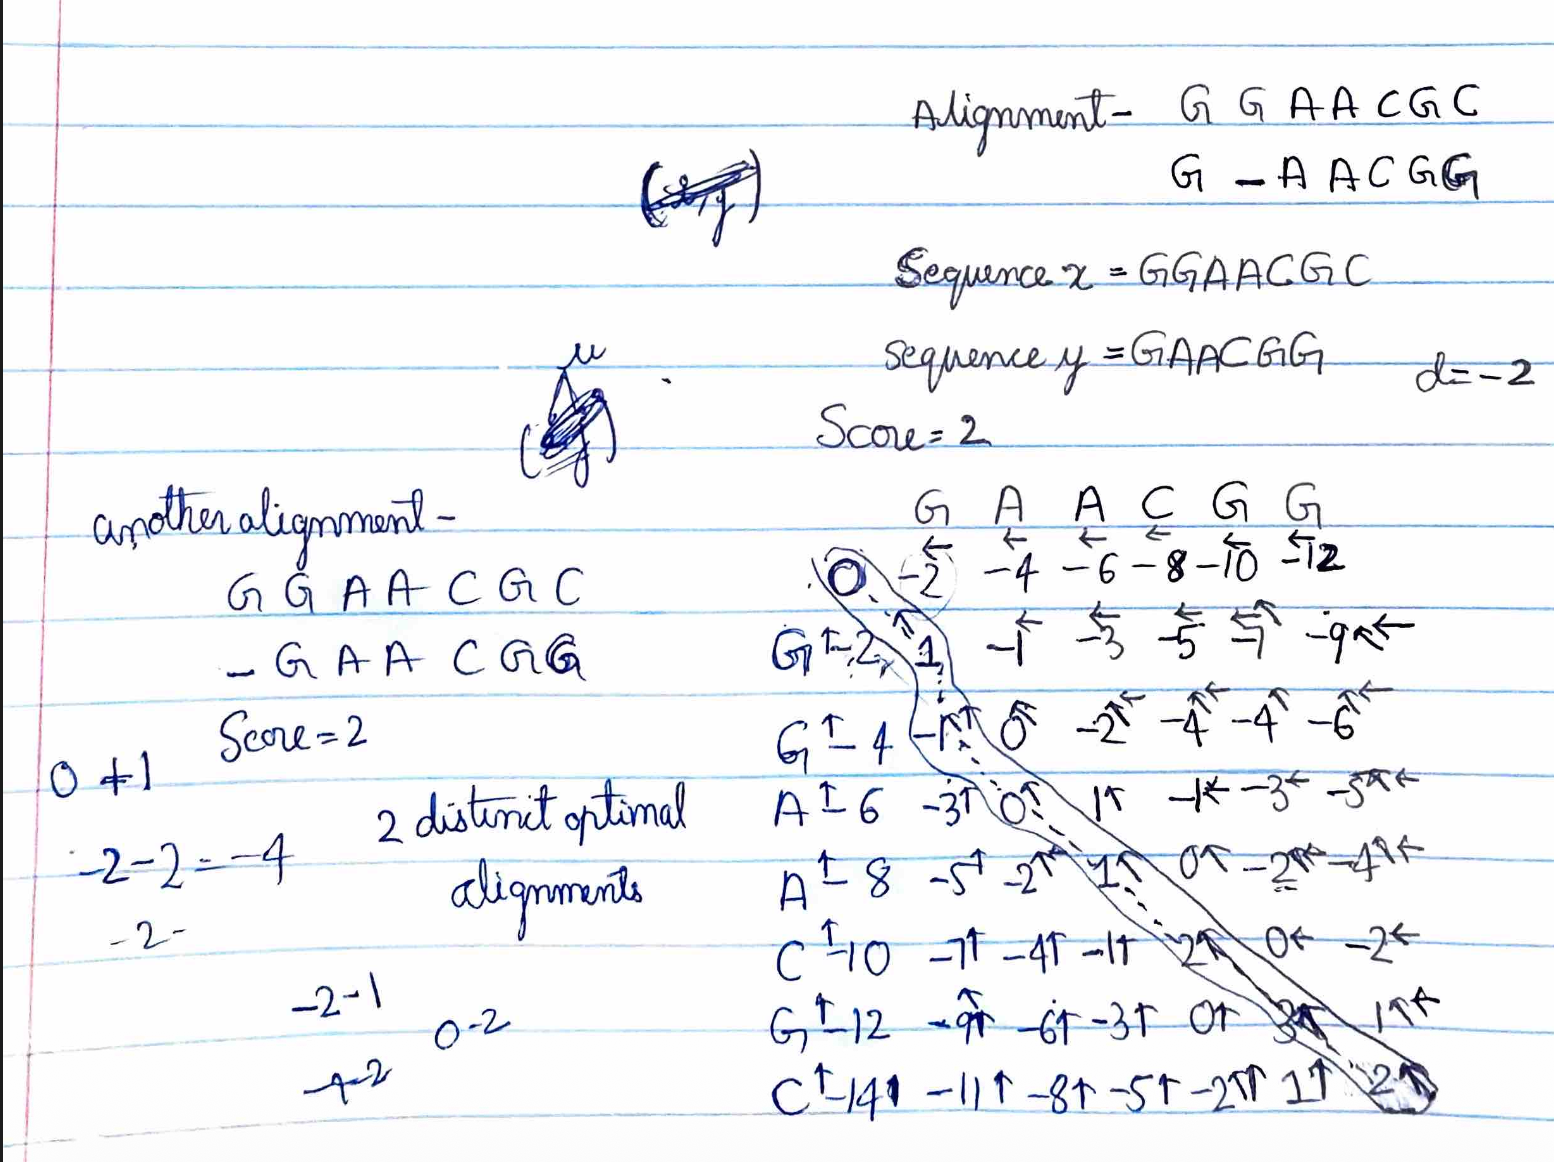

### Background

**Local sequence alignment** finds the highest-scoring aligned subsequence between two sequences, ignoring poorly matching regions at either end. The **Smith-Waterman** algorithm [2] solves this with a small but important modification to the Needleman-Wunsch recurrence — a fourth option of $0$ is added, which allows the alignment to restart rather than carry forward a negative score:

$H(i, j) = \max \begin{cases} 0 & \text{(restart)} \\ H(i-1,\, j-1) + s(x_i, y_j) & \text{(match or substitution)} \\ H(i-1,\, j) - d & \text{(gap in } y \text{)} \\ H(i,\, j-1) - d & \text{(gap in } x \text{)} \end{cases}$

The scoring scheme is identical to Part 1: match $= +1$, mismatch $= -1$, linear gap penalty $d = 2$.

Initialization also differs from Needleman-Wunsch: the **entire first row and first column are set to $0$** (rather than increasing gap penalties), reflecting the fact that a local alignment can begin anywhere in either sequence.

The traceback also differs: rather than starting at the bottom-right corner, you **begin at the cell with the highest score in the entire matrix** and follow back pointers until you reach a cell with value $0$.

---

### Task

You are given two sequences:

- Sequence $x$: `GGAGTATCAG`
- Sequence $y$: `TAAGAGTACA`

Using the scoring scheme above, perform a local alignment of these two sequences **by hand**.

**Step 1 — Fill in the $H$ matrix.**
Compute every entry using the Smith-Waterman recurrence above. Draw a back pointer for each cell toward the direction(s) that produced the maximum score. Cells with value $0$ due to the restart condition do not require a back pointer.

**Step 2 — Traceback.**
Identify the cell with the maximum value in the matrix — this is your alignment start. Follow back pointers until you reach a cell with value $0$. As in Part 1, if multiple back pointers exist at any cell, explore all branches and report every distinct optimal local alignment along with its score.

> **Submission:** Include a clear photo or digital drawing of your $H$ matrix and traceback path(s) alongside your typed alignments.

> **When you are done:** open `docs/module-3-problem-2-answers.html` in a browser to check both parts. It shows each matrix with its back pointers, the traceback paths, and every optimal alignment. Fill in your matrices first.

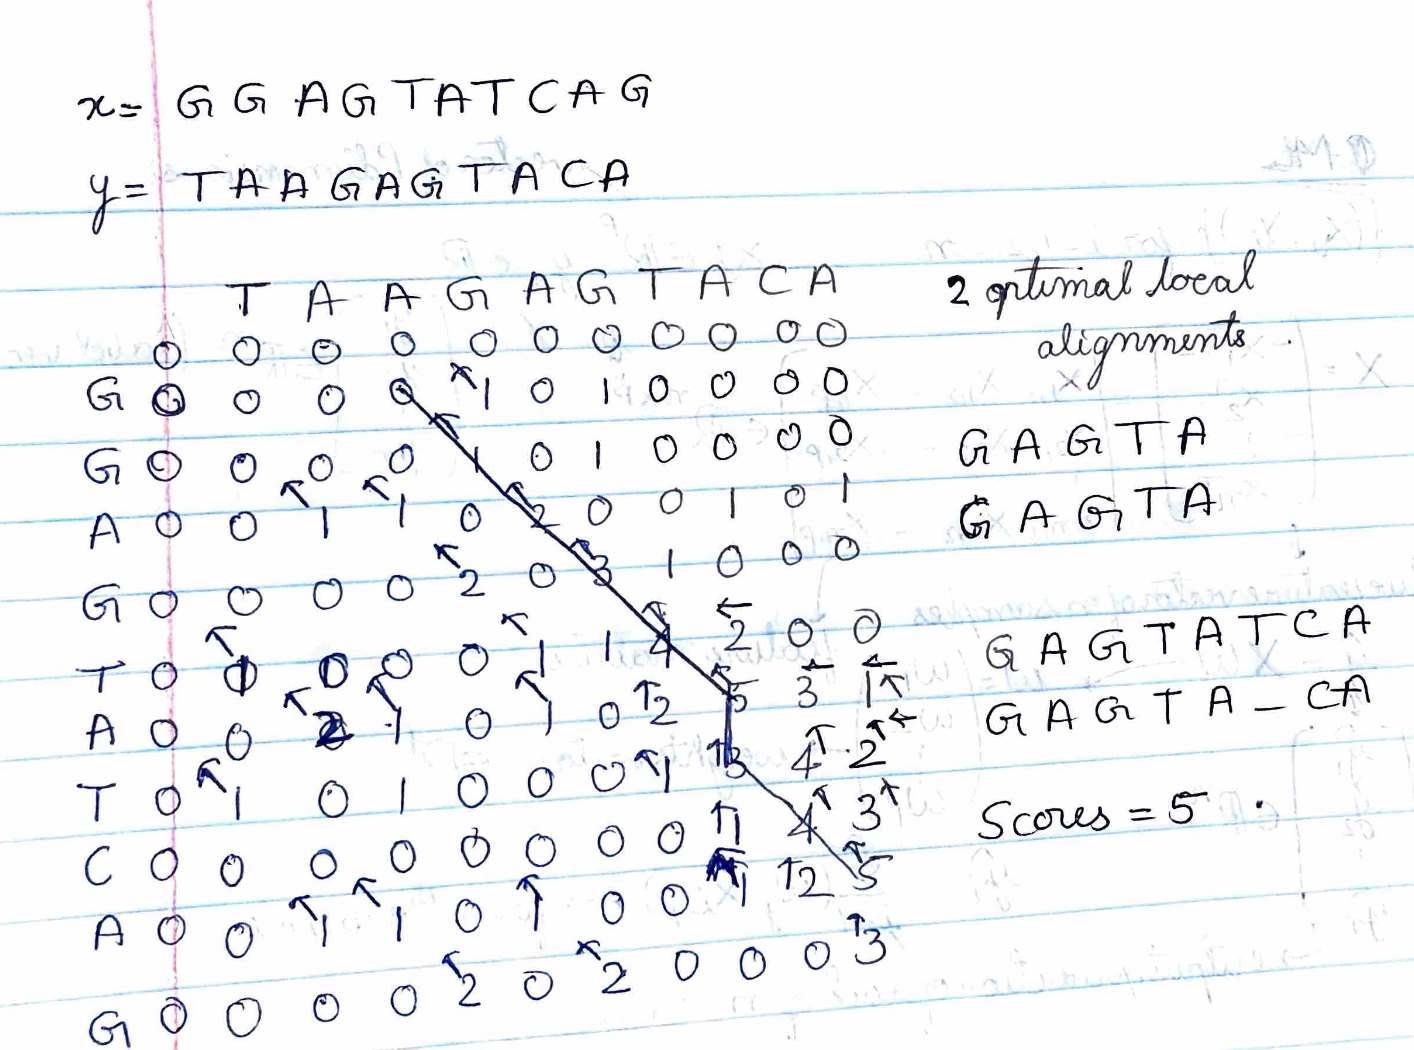

## References

[1] Needleman, S.B. & Wunsch, C.D. (1970). A general method applicable to the search for similarities in the amino acid sequence of two proteins. *Journal of Molecular Biology*, 48(3), 443–453. https://doi.org/10.1016/0022-2836(70)90057-4. PDF in [`research/`](../research/needleman-wunsch-1970-similarities-in-amino-acid-sequence.pdf)

[2] Smith, T.F. & Waterman, M.S. (1981). Identification of common molecular subsequences. *Journal of Molecular Biology*, 147(1), 195–197. https://doi.org/10.1016/0022-2836(81)90087-5. PDF in [`research/`](../research/smith-waterman-1981-common-molecular-subsequences.pdf)